# Finding the fatigue strength with active learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/digiLab-ai/dbtt-active-learning/blob/main/Fatigue_active_learning.ipynb)

An S–N programme exists to answer one question: **what stress amplitude can
this material survive for its design life, and how sure are we?** Fatigue
specimens are cheap to make and expensive to run — a single long test ties up a
rig for weeks — so the programme should spend them where they tell us most.

This notebook does the whole thing end to end, against a live
[Uncertainty Engine](https://uncertaintyengine.ai) project:

| Section | What it does |
| --- | --- |
| [1. A simulated S–N programme](#scrollTo=section-1) | An S–N simulator stands in for the test house, so every estimate can be scored against a known truth |
| [2. Active learning on the Engine](#scrollTo=section-2) | Five workflows — train, recommend, visualise, predict, validate — saved to the project and driven in a loop |
| [3. The fatigue strength, with its uncertainty](#scrollTo=section-3) | The $10^7$ cycle strength read off the trained model, with the uncertainty that comes with it |
| [4. Was the active learning worth it?](#scrollTo=section-4) | Three fixed designs through the same machinery, for comparison |

Life is modelled with a **Stromeyer** S–N curve — Basquin's power law with an
endurance limit $S_e$ underneath it:

$$\log_{10} N_f \;=\; A - B\,\log_{10}\!\left(S_a - S_e\right), \qquad S_a > S_e$$

so life runs away as the amplitude approaches $S_e$ from above and the curve
never crosses it. Scatter is in log life and widens as the tests get longer,
$\sigma_{\log} = \sigma_\mathrm{base} + \sigma_\mathrm{rel}\max(0, \log_{10}N_f - \text{knee})$.

> **Runouts are real, and they are the hard part.** A specimen that survives
> the rig's cycle limit has not told you its life, only that its life exceeds
> the limit. That is a **censored** observation, and this notebook records it
> at the limit and trains on it like any other number — which is what a GP
> regression forces you to do and is *not* correct. Section 3 and the notes say
> where that bites, and it bites hardest in exactly the low-amplitude region
> the fatigue strength is read from.

> **Everything you might want to change is in [Settings](#scrollTo=settings),**
> the first cell below. Nothing further down needs editing to re-run on a
> different material or a different programme.

> **The code lives in collapsed cells.** Each one is titled with what it
> covers; click the title to unfold it. Nothing is imported from this
> repository, so the notebook runs anywhere its dependencies do.

---
## Dependencies

The first cell installs whatever the runtime is missing and leaves a satisfied environment alone.

In [1]:
import importlib
import importlib.metadata as metadata
import importlib.util
import subprocess
import sys

#: (import name, distribution name, pip specifier). The import name is what
#: this notebook uses; the distribution name is what carries the version, and
#: the two differ often enough to be worth keeping apart.
REQUIREMENTS = [
    ("uncertainty_engine", "uncertainty-engine", "uncertainty-engine>=0.15,<0.16"),
    ("dotenv", "python-dotenv", "python-dotenv>=1.0"),
    ("pydantic", "pydantic", "pydantic>=2.6"),
    # Needed to compare the versions above against their specifiers. Without
    # it the check below degrades to "is it present at all", which is how an
    # SDK too old to work got through on a local kernel once already.
    ("packaging", "packaging", "packaging>=23.0"),
]


def _version(distribution: str):
    """The installed version of a distribution, or None if it is absent."""
    try:
        return metadata.version(distribution)
    except metadata.PackageNotFoundError:
        return None


def _satisfied(module: str, distribution: str, spec: str) -> bool:
    """Whether the right distribution is present at an acceptable version."""
    have = _version(distribution)
    if have is None or importlib.util.find_spec(module) is None:
        return False
    try:
        from packaging.requirements import Requirement
    except ImportError:
        return True  # cannot check the range here; presence will have to do
    return Requirement(spec).specifier.contains(have, prereleases=True)


missing = [spec for module, dist, spec in REQUIREMENTS
           if not _satisfied(module, dist, spec)]

if missing:
    # Deliberately not the %pip magic. It hands its line to a shell, and the
    # shell reads the < and > of a version specifier as redirections: it
    # writes a file called "=0.15," and then fails on a missing "=0.16"
    # without pip ever running - and without raising, so the notebook carries
    # on to the imports and dies there, pointing at the wrong cell. An argv
    # list has no shell in it to misread.
    print("installing:", ", ".join(missing))
    done = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", *missing],
        capture_output=True, text=True,
    )
    if done.returncode != 0:
        raise RuntimeError("pip could not install the dependencies:\n\n"
                           + (done.stderr or done.stdout).strip())
    importlib.invalidate_caches()

# Say plainly what is wrong, here, rather than failing in a later cell with a
# traceback that points at the import instead of at the environment.
for module, dist, spec in REQUIREMENTS:
    if _satisfied(module, dist, spec):
        print(f"  {dist} {_version(dist)}")
        continue

    found = importlib.util.find_spec(module)
    detail = [f"{dist} is installed at {_version(dist)}, which does not satisfy {spec!r}."]
    if found is not None and found.origin:
        detail.append(f"  the import `{module}` resolves to: {found.origin}")
        detail.append("  If another distribution provides that same import name - the "
                      "in-process modelling library shares it with the SDK - then no "
                      "amount of installing will help, and the fix is to change "
                      "environment or kernel.")
    if module in sys.modules:
        detail.append(f"  `{module}` is already imported in this session, so an "
                      "upgrade will not take effect until the runtime is restarted.")
    raise RuntimeError("\n".join(detail))

  uncertainty-engine 0.15.0
  python-dotenv 1.2.3
  pydantic 2.13.5
  packaging 26.3


In [2]:
import io
import os
import tempfile
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, Dict, List, Optional, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pydantic import BaseModel, ConfigDict, Field, model_validator

from importlib.metadata import version

print(f"uncertainty-engine SDK {version('uncertainty-engine')}")

uncertainty-engine SDK 0.15.0


---
<a id="settings"></a>
## Settings

Everything meant to be changed lives in the next cell. Nothing below it needs
editing to re-run this notebook on a different material, a different programme
or a different model.

The first two groups describe the **material the simulator fatigues** — in a
real programme they are the unknown the testing exists to find, and here they
are the ground truth every estimate is scored against. The rest configure the
campaign, the Engine model, and the figures.

In [3]:
# ====================== THE MATERIAL (ground truth) ======================
# A real programme does not know these. The simulator does, so the notebook
# can score itself. Stromeyer S-N curve:
#
#   log10(N_f) = A - B * log10(S_a - S_e),   S_a > S_e
#
# The constants below are pinned so that the curve passes through 250 MPa at
# 10^7 cycles and 500 MPa at 10^4 cycles, which makes the answer this notebook
# is trying to recover exactly 250.0 MPa.
TRUE_ENDURANCE_LIMIT = 230.0   # MPa  S_e, the asymptote life runs away at
TRUE_BASQUIN_A       = 10.454  # -    intercept of the Stromeyer line
TRUE_BASQUIN_B       =  2.655  # -    slope; larger means a flatter S-N curve

# ===================== THE RIG ===========================================
# A specimen that reaches the cycle limit without failing is a RUNOUT: the
# test is stopped and the life recorded as the limit. That number is a lower
# bound, not a measurement, and the notebook is explicit about what it costs.
RUNOUT_LOG_CYCLES = 8.0     # log10 cycles  where the rig gives up (10^8)

# ===================== MEASUREMENT SCATTER ===============================
# sigma = NOISE_BASE + NOISE_RELATIVE * max(0, log10(N_f) - NOISE_KNEE),
# in decades of life. Fatigue scatter is quoted as a factor on life, so it
# belongs in log space, and it widens sharply near the endurance limit.
NOISE_BASE     = 0.10       # decades  scatter floor, on a short test
NOISE_RELATIVE = 0.06       # decades per decade of life beyond the knee
NOISE_KNEE     = 4.0        # log10 cycles  where the scatter starts to widen
SIMULATOR_SEED = 0          # reproducible specimens; None for a fresh programme

# ===================== THE CAMPAIGN ======================================
# The lower bound sits just above S_e: below it every specimen is a runout and
# the test tells you almost nothing.
BOUNDS               = (233.0, 550.0)   # testable stress amplitude [MPa]
SEED_STRESSES        = [233.0, 550.0]   # the initial design
ITERATIONS           = 6                # active-learning iterations
POINTS_PER_ITERATION = 1                # specimens chosen per iteration

# ===================== THE QUESTION ======================================
# The fatigue strength: the amplitude whose life is exactly TARGET_CYCLES.
# Read off the fitted curve, exactly as the DBTT notebook reads a transition.
TARGET_CYCLES = 1.0e7       # cycles  the design life

# ===================== THE MODEL =========================================
# Straight through to the Engine's ModelConfig and Recommend nodes.
KERNEL      = "LIN+RBF"            # LIN M12 M32 M52 PER RBF RQF, composed
                                   # with + (additive) and * (multiplicative),
                                   # e.g. "(M52*PER)+RQF". LIN carries the
                                   # falling trend; RBF picks up the knee.
MODEL_TYPE  = "SingleTaskGPTorch"  # or SingleTaskVariationalGPTorch
WARP_INPUTS = False                # learn a transformation of the input space;
                                   # worth trying here, where the curve varies
                                   # far faster near the limit than above it
MODEL_SEED  = 0

ACQUISITION = "qNIPV"              # see ACQUISITIONS in section 2 for the rest

# The GP's MEAN FUNCTION is deliberately absent from this list: the Engine
# does not expose it. `ModelConfig` takes a kernel, not a mean, and
# `TrainModel` takes only (config, inputs, outputs). The kernel is the lever
# you have - the LIN term in the default "LIN+RBF" is what lets the fit carry
# a linear trend, which is most of what a non-constant mean would buy you here.

# ===================== PLOT COLOURS ======================================
COLOURS = {
    "truth":      "0.4",   # the true S-N curve
    "gp":         "C0",    # GP mean and band, in the per-iteration panels
    "posterior":  "C3",    # the final GP posterior, section 3
    "tests":      "C1",    # specimens that failed
    "runout":     "C7",    # specimens that survived the cycle limit
    "picked":     "C3",    # where the acquisition chose to test next
    "strength":   "C3",    # the fatigue strength estimated from the model
    "true_strength": "C2", # the fatigue strength the simulator actually implies
    "limit":      "C4",    # the true endurance limit
}

### Credentials

The notebook talks to a live Engine project, so it needs `UE_USERNAME`,
`UE_PASSWORD` and `UE_PROJECT_NAME`.

**In Colab**, put them in the Secrets panel — the 🔑 key icon in the left
sidebar — with *Notebook access* switched on for each.

**Locally**, put them in a `.env` file beside this notebook. `.env` is
gitignored; copy `.env.example` rather than editing it, so the template keeps
its keys blank.

`UE_PROJECT_NAME` must name a project that **already exists**: projects are
created in the Engine GUI, not from the SDK. `load_credentials()` reports only
*where* the credentials came from, never what they are, so the output of these
cells is safe to commit.

In [4]:
#@title Credentials and connection { display-mode: "form" }
# Covers
#   load_credentials()   Colab secrets first, then `.env`, then the environment.
#                        Returns only *where* they came from, never the values.
#   project_name()       the Engine project to work in, from $UE_PROJECT_NAME.
#   connect()            authenticate and resolve (client, project_id).
#
# Projects are created in the Uncertainty Engine GUI, not from the SDK, so the
# project named here must already exist.

CREDENTIAL_KEYS = ("UE_USERNAME", "UE_PASSWORD")
PROJECT_KEY = "UE_PROJECT_NAME"


def load_credentials(env_path: str = ".env") -> str:
    """Load Engine credentials into the process environment.

    Returns ``"colab"``, ``"dotenv"``, ``"environment"`` or ``"missing"``. The
    values themselves are never returned or logged, so the output of this cell
    is safe to commit with the notebook.
    """
    keys = CREDENTIAL_KEYS + (PROJECT_KEY,)

    try:  # Google Colab secrets (the key icon in the left sidebar)
        from google.colab import userdata  # type: ignore

        found = False
        for key in keys:
            try:
                os.environ[key] = userdata.get(key)
                found = True
            except Exception:
                pass
        if found:
            return "colab"
    except ImportError:
        pass

    path = Path(env_path)
    if path.exists():
        from dotenv import load_dotenv

        load_dotenv(path)
        return "dotenv"

    if all(os.environ.get(key) for key in CREDENTIAL_KEYS):
        return "environment"
    return "missing"


def credentials_present() -> bool:
    """Whether every credential key is set. Does not read the values."""
    return all(os.environ.get(key) for key in CREDENTIAL_KEYS)


def project_name(override: Optional[str] = None) -> str:
    """The Engine project to work in: ``override``, else ``$UE_PROJECT_NAME``."""
    name = override or os.environ.get(PROJECT_KEY)
    if not name:
        raise RuntimeError(
            f"No Engine project named. Set {PROJECT_KEY} in your .env (or in "
            "Colab secrets), or pass project_name=... explicitly. Projects are "
            "created in the Uncertainty Engine GUI, not from the SDK."
        )
    return name


def connect(name: Optional[str] = None):
    """Authenticate and resolve a project id. Returns ``(client, project_id)``."""
    from uncertainty_engine import Client

    if not credentials_present():
        raise RuntimeError(
            "Uncertainty Engine credentials are not set. Put "
            f"{' and '.join(CREDENTIAL_KEYS)} in a .env file beside this "
            "notebook, or in Colab secrets, then re-run load_credentials()."
        )

    client = Client()
    client.authenticate()
    return client, client.projects.get_project_id_by_name(project_name(name))

In [5]:
source = load_credentials()
print(f"credentials loaded from: {source}")

client, project_id = connect()
print(f"project: {project_name()}")

credentials loaded from: dotenv


project: Test


---
<a id="section-1"></a>
## 1. A simulated S–N programme

The simulator stands in for the test house. It follows the uncertainty-engine
`Simulator` contract — config-driven construction, a leaf `_forward(X)` holding
the raw $X \to y$ map, and the public verb `simulate(X)` returning a
`SimulationResult` — so code written against it ports to the real thing with a
change of import.

Because it is a simulator it knows the answer, and that is the point: every
estimate later in the notebook can be scored against a fatigue strength we
actually know.

$y$ is $\log_{10}$ of the cycles to failure, not the cycles themselves. Life
spans five decades across this stress range, and a GP fitted to raw cycles
would spend all its flexibility on the short tests and none on the long ones.

In [6]:
#@title The S-N simulator { display-mode: "form" }
# Covers
#   StromeyerParams / RigParams / NoiseParams / SpecimenParams /
#   FatigueSimulatorConfig
#                        validated pydantic config; a whole programme is
#                        reproducible from these fields alone.
#   SimulationResult     what `simulate` returns: `y` plus auxiliary payload.
#   Simulator            the uncertainty-engine `Simulator` noun, in miniature:
#                        config-driven construction, a leaf `_forward(X)`
#                        implementing the raw X -> y map, and the public verb
#                        `simulate(X)`. Code written against it ports to the
#                        engine with a change of import.
#   FatigueSimulator     stress amplitude [MPa] -> log10 cycles to failure, as
#                        a Stromeyer curve plus scatter in log life, censored
#                        at the rig's cycle limit. `run()` returns test-house-
#                        shaped rows.
#   plot_dataset         the S-N diagram, failures and runouts drawn apart.
#
# The forward map is *stochastic*: one `simulate` call is one specimen taken to
# failure (or to the cycle limit), a single realisation rather than a summary
# of the output law.

#: Column headers of the test-result table, matching the test-house spreadsheet.
COLUMNS = [
    "Material", "Condition", "Processing", "Surface finish",
    "Specimen ID", "Specimen Type", "Loading", "Stress ratio R",
    "Stress amplitude (MPa)", "Cycles to failure", "log10 cycles", "Runout",
]

STRESS_COL = "Stress amplitude (MPa)"
CYCLES_COL = "Cycles to failure"
LOG_CYCLES_COL = "log10 cycles"
RUNOUT_COL = "Runout"


class SimulationResult(BaseModel):
    """`y` is the canonical output of the forward map; `outputs` is everything else."""

    model_config = ConfigDict(arbitrary_types_allowed=True)

    y: Any = Field(None, description="Canonical output(s) of the forward map X -> y.")
    outputs: Dict[str, Any] = Field(
        default_factory=dict,
        description="Auxiliary payload: diagnostics, provenance, units, ground truth.",
    )


class StromeyerParams(BaseModel):
    """A Stromeyer S-N curve: Basquin's law with an endurance limit under it.

        log10(N_f) = A - B * log10(S_a - S_e),   S_a > S_e

    Life runs away as the amplitude approaches ``endurance_limit`` from above,
    so the curve has a vertical asymptote there and no finite life below it.
    """

    model_config = ConfigDict(extra="forbid")

    endurance_limit: float = Field(
        230.0, gt=0.0, description="Stress amplitude S_e the curve is asymptotic to [MPa]."
    )
    intercept: float = Field(10.454, description="A, the Stromeyer intercept [-].")
    slope: float = Field(2.655, gt=0.0, description="B, the Stromeyer slope [-].")


class RigParams(BaseModel):
    """The test rig's cycle limit, which is what creates runouts."""

    model_config = ConfigDict(extra="forbid")

    runout_log_cycles: float = Field(
        8.0, gt=0.0,
        description="log10 cycles at which an unfailed test is stopped and censored.",
    )


class NoiseParams(BaseModel):
    """Scatter in log life, widening beyond a knee [decades]."""

    model_config = ConfigDict(extra="forbid")

    base: float = Field(0.10, ge=0.0, description="Scatter floor [decades of life].")
    relative: float = Field(
        0.06, ge=0.0, description="Added scatter per decade beyond the knee."
    )
    knee: float = Field(4.0, description="log10 cycles beyond which scatter widens.")


class SpecimenParams(BaseModel):
    """Specimen provenance carried through to the test-result table."""

    model_config = ConfigDict(extra="forbid")

    material: str = Field("316L stainless", description="Material designation.")
    condition: str = Field("Solution annealed", description="Material condition.")
    processing: str = Field("Hot rolled", description="Processing route.")
    surface_finish: str = Field("Ground, Ra 0.2 um", description="Specimen surface finish.")
    specimen_type: str = Field("Plain cylindrical", description="Test specimen type.")
    loading: str = Field("Axial, constant amplitude", description="Loading mode.")
    stress_ratio: float = Field(-1.0, description="Stress ratio R = S_min / S_max.")
    id_prefix: str = Field("FAT2025-", description="Prefix for generated specimen IDs.")
    id_digits: int = Field(4, ge=1, description="Zero-padded width of the specimen ID.")


class FatigueSimulatorConfig(BaseModel):
    """Everything `FatigueSimulator` needs, as validated fields."""

    model_config = ConfigDict(extra="forbid")

    name: str = Field("316l_sn", description="Short name for this programme.")
    description: Optional[str] = Field(None, description="Free-text note.")
    curve: StromeyerParams = Field(default_factory=StromeyerParams)
    rig: RigParams = Field(default_factory=RigParams)
    noise: NoiseParams = Field(default_factory=NoiseParams)
    specimen: SpecimenParams = Field(default_factory=SpecimenParams)
    seed: Optional[int] = Field(0, description="Random seed. None gives non-reproducible draws.")
    stress_range: tuple = Field(
        (231.0, 700.0), description="Physically sensible stress-amplitude bounds [MPa]."
    )

    @model_validator(mode="after")
    def _check_range(self) -> "FatigueSimulatorConfig":
        lo, hi = self.stress_range
        if hi <= lo:
            raise ValueError("stress_range must be (low, high) with high > low")
        if lo <= self.curve.endurance_limit:
            raise ValueError(
                f"stress_range starts at {lo} MPa, at or below the endurance limit "
                f"({self.curve.endurance_limit} MPa), where the curve has no finite life"
            )
        return self


class Simulator:
    """Abstract base for all simulators: the ``X -> y`` forward map.

    Construction is config-driven; ``X`` is an argument to ``simulate``, never
    stored on the config.
    """

    def __init__(self, config) -> None:
        self.config = config

    def _forward(self, X):
        """Evaluate the raw forward map ``X -> y``. Leaves implement this."""
        raise NotImplementedError

    def simulate(self, X) -> SimulationResult:
        """One evaluation of the forward map, wrapped in a result."""
        return self.build_result(X, self._forward(X))

    def build_result(self, X, y) -> SimulationResult:
        """The extension point every ``simulate`` goes through."""
        return SimulationResult(y=y)

    @classmethod
    def describe(cls) -> Dict[str, Any]:
        """Introspect the leaf without instantiating it."""
        return {
            "name": cls.__name__,
            "summary": (cls.__doc__ or "").strip().split("\n")[0],
        }


class FatigueSimulator(Simulator):
    """S-N test: stress amplitude [MPa] -> log10 cycles to failure.

    Repeated calls at the same amplitude give different lives, as in a real
    programme. A specimen that reaches the rig's cycle limit is recorded at
    the limit and flagged as a runout.
    """

    def __init__(self, config: Optional[FatigueSimulatorConfig] = None) -> None:
        super().__init__(config or FatigueSimulatorConfig())
        self._rng = np.random.default_rng(self.config.seed)

    # ----- the forward map -----
    def _forward(self, X) -> np.ndarray:
        """Draw noisy log10 lives, censored at the cycle limit. Advances the state."""
        stress = self._as_array(X)
        self._validate(stress)
        drawn = self._rng.normal(loc=self.true_log_life(stress),
                                 scale=self.noise_std(stress))
        return np.minimum(drawn, self.config.rig.runout_log_cycles)

    def build_result(self, X, y) -> SimulationResult:
        """Wrap the measurement, carrying the ground truth as auxiliary payload.

        ``outputs["true_log_life"]`` and ``outputs["noise_std"]`` have **no
        counterpart in a real experiment**. They are here to score how well the
        active learning recovers the truth, and must never be fed to the GP.
        ``outputs["runout"]`` *does* have a counterpart: the test house knows
        perfectly well which specimens it stopped.
        """
        stress = self._as_array(X)
        return SimulationResult(
            y=y,
            outputs={
                "stress": stress,
                "true_log_life": self.true_log_life(stress),
                "noise_std": self.noise_std(stress),
                "runout": y >= self.config.rig.runout_log_cycles,
                "units": {"stress": "MPa", "life": "cycles"},
            },
        )

    # ----- ground truth (simulator-only) -----
    def true_log_life(self, stress) -> np.ndarray:
        """Noise-free log10 cycles to failure at the given amplitude(s) [MPa].

        Uncensored: this is the life the specimen *would* reach, which beyond
        the rig's limit is a number no experiment can observe.
        """
        curve = self.config.curve
        above = np.asarray(stress, dtype=float) - curve.endurance_limit
        return curve.intercept - curve.slope * np.log10(above)

    def noise_std(self, stress) -> np.ndarray:
        """Scatter [decades] at the given amplitude(s). Widens beyond the knee."""
        noise = self.config.noise
        beyond = np.maximum(0.0, self.true_log_life(stress) - noise.knee)
        return noise.base + noise.relative * beyond

    def strength_for_life(self, log_life: float) -> float:
        """The amplitude [MPa] whose true life is ``log_life``. The answer.

        Inverting the Stromeyer form directly, since it has a closed form and
        exactly one root above the endurance limit.
        """
        curve = self.config.curve
        return float(curve.endurance_limit
                     + 10.0 ** ((curve.intercept - log_life) / curve.slope))

    @property
    def endurance_limit(self) -> float:
        """The amplitude [MPa] below which the true curve has no finite life."""
        return self.config.curve.endurance_limit

    # ----- test-campaign convenience -----
    def run(self, stresses, start_index: int = 1) -> pd.DataFrame:
        """Fatigue specimens at ``stresses`` and return a test-result table.

        The table carries only what a real test house would report: the
        noise-free truth stays on the `SimulationResult` and never reaches the
        dataset. ``start_index`` continues the specimen numbering.
        """
        result = self.simulate(stresses)
        stress = result.outputs["stress"]
        spec = self.config.specimen
        numbers = np.arange(start_index, start_index + stress.size)

        return pd.DataFrame(
            {
                "Material": spec.material,
                "Condition": spec.condition,
                "Processing": spec.processing,
                "Surface finish": spec.surface_finish,
                "Specimen ID": [
                    f"{spec.id_prefix}{n:0{spec.id_digits}d}" for n in numbers
                ],
                "Specimen Type": spec.specimen_type,
                "Loading": spec.loading,
                "Stress ratio R": spec.stress_ratio,
                STRESS_COL: np.round(stress, 2),
                CYCLES_COL: np.round(10.0 ** result.y).astype("int64"),
                LOG_CYCLES_COL: np.round(result.y, 4),
                RUNOUT_COL: result.outputs["runout"],
            },
            columns=COLUMNS,
        )

    # ----- plumbing -----
    @staticmethod
    def _as_array(X) -> np.ndarray:
        if isinstance(X, pd.DataFrame):
            return X[STRESS_COL].to_numpy(dtype=float)
        return np.atleast_1d(np.asarray(X, dtype=float))

    def _validate(self, stress: np.ndarray) -> None:
        lo, hi = self.config.stress_range
        bad = stress[(stress < lo) | (stress > hi)]
        if bad.size:
            raise ValueError(
                f"Stress amplitude(s) {np.unique(bad).tolist()} outside the "
                f"configured range [{lo}, {hi}] MPa."
            )


def plot_dataset(data: pd.DataFrame, ax=None):
    """The S-N diagram, with runouts drawn as the lower bounds they are."""
    if ax is None:
        _, ax = plt.subplots(figsize=(7.5, 4.5))

    failed = data[~data[RUNOUT_COL].astype(bool)]
    survived = data[data[RUNOUT_COL].astype(bool)]

    ax.scatter(failed[LOG_CYCLES_COL], failed[STRESS_COL], s=45, zorder=3,
               color="k", label=f"failed ({len(failed)})")
    if len(survived):
        ax.scatter(survived[LOG_CYCLES_COL], survived[STRESS_COL], s=70, zorder=3,
                   marker=">", facecolor="none", edgecolor="k",
                   label=f"runout ({len(survived)})")

    ax.set_xlabel(LOG_CYCLES_COL)
    ax.set_ylabel(STRESS_COL)
    ax.set_title("S-N diagram")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
    return ax

In [7]:
simulator = FatigueSimulator(
    FatigueSimulatorConfig(
        curve=StromeyerParams(
            endurance_limit=TRUE_ENDURANCE_LIMIT,
            intercept=TRUE_BASQUIN_A,
            slope=TRUE_BASQUIN_B,
        ),
        rig=RigParams(runout_log_cycles=RUNOUT_LOG_CYCLES),
        noise=NoiseParams(base=NOISE_BASE, relative=NOISE_RELATIVE, knee=NOISE_KNEE),
        seed=SIMULATOR_SEED,
    )
)
print(FatigueSimulator.describe())
print(f"endurance limit: {simulator.endurance_limit:g} MPa")

{'name': 'FatigueSimulator', 'summary': 'S-N test: stress amplitude [MPa] -> log10 cycles to failure.'}
endurance limit: 230 MPa


### One test

One call is one specimen taken to failure. `y` is the $\log_{10}$ life the test house would report; `outputs` carries the ground truth beside it, which a real test never does.

In [8]:
result = simulator.simulate([300.0])
print(f"log10 cycles: {result.y[0]:.3f}  -> {10 ** result.y[0]:,.0f} cycles")
result.outputs

log10 cycles: 5.580  -> 379,813 cycles


{'stress': array([300.]),
 'true_log_life': array([5.5552647]),
 'noise_std': array([0.19331588]),
 'runout': array([False]),
 'units': {'stress': 'MPa', 'life': 'cycles'}}

Test at the same amplitude twice and you get two different lives. That scatter is the whole reason the answer needs an interval — and in fatigue it is large enough that a factor of two in life is unremarkable.

In [9]:
repeats = [simulator.simulate([300.0]).y[0] for _ in range(5)]
print("log10 lives:", [round(v, 3) for v in repeats])
print("as cycles:  ", [f"{10 ** v:,.0f}" for v in repeats])

log10 lives: [np.float64(5.53), np.float64(5.679), np.float64(5.576), np.float64(5.452), np.float64(5.625)]
as cycles:   ['338,631', '477,605', '376,308', '282,951', '421,858']


A specimen just above the endurance limit will not fail at all. The rig stops it at its cycle limit and the row comes back flagged as a runout — a lower bound on the life, recorded as if it were the life.

In [10]:
edge = simulator.run([234.0])
print(f"true life would have been 10**{simulator.true_log_life(234.0):.2f} cycles")
edge[[STRESS_COL, CYCLES_COL, LOG_CYCLES_COL, RUNOUT_COL]]

true life would have been 10**8.86 cycles


,Stress amplitude (MPa),Cycles to failure,log10 cycles,Runout
0,234.0,100000000,8.0,True


### The initial design

**Two specimens, one at each end.** `Recommend` is given no bounds of its own —
it searches the domain the trained model has seen — so the seed design is what
tells the acquisition how far it may roam.

The low-amplitude end is where the interesting behaviour is and also where the
rig runs out of patience: a specimen at 233 MPa has a true life of $10^{9.2}$
cycles, so it will be stopped at the limit and recorded as a runout.

> **A note on axes.** The S–N diagram above is drawn the way a test report
> draws it, life across and amplitude up. Every model figure from here on is
> drawn the other way up — amplitude across, life up — because the GP maps
> amplitude to life, and the fatigue strength is read *along the amplitude
> axis* where the fitted curve crosses the design life.

In [11]:
campaign = simulator.run(SEED_STRESSES, start_index=1)
campaign

,Material,Condition,Processing,Surface finish,Specimen ID,Specimen Type,Loading,Stress ratio R,Stress amplitude (MPa),Cycles to failure,log10 cycles,Runout
0,316L stainless,Solution annealed,Hot rolled,"Ground, Ra 0.2 um",FAT2025-0001,Plain cylindrical,"Axial, constant amplitude",-1.0,233.0,100000000,8.0000,True
1,316L stainless,Solution annealed,Hot rolled,"Ground, Ra 0.2 um",FAT2025-0002,Plain cylindrical,"Axial, constant amplitude",-1.0,550.0,5401,3.7325,False


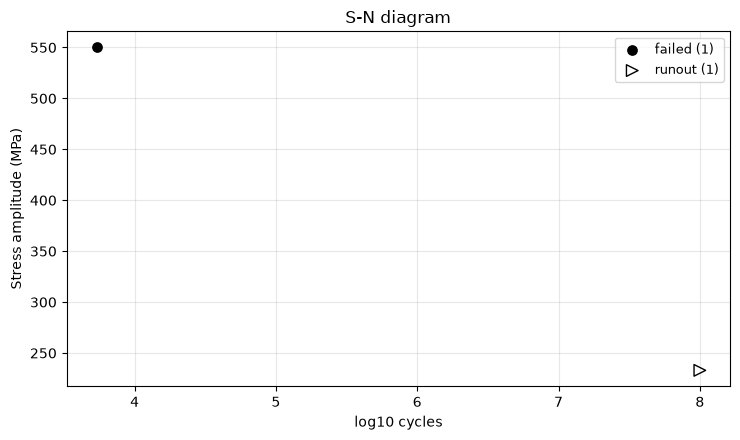

In [12]:
plot_dataset(campaign)
plt.tight_layout()
plt.show()

---
<a id="section-2"></a>
## 2. Active learning on the Engine

Everything that models — the GP, the acquisition, the scoring — runs on the
**remote Uncertainty Engine**, not in this process. The cell below assembles
five workflow graphs and saves them to the project, after which they are
visible in the Engine GUI and can be inspected, re-run and edited there. That
is the point of building them programmatically rather than only executing them.

| Workflow | Nodes | Purpose |
| --- | --- | --- |
| **Train model** | `LoadDataset` → `FilterDataset` ×2 → `ModelConfig` → `TrainModel` → `Save` | Fit a GP to the programme so far |
| **Active Learning** | `LoadModel` → `Recommend` → `Save` | Which amplitude to test next |
| **GP plot** | `LoadModel` + `CreateDatasetSlice` → `PredictModel` → `UncertaintyPlot` | The posterior, returned inline with the job |
| **Predict slice** | `LoadModel` + `CreateDatasetSlice` → `PredictModel` → `Save` ×2 | The same posterior, **saved** as project datasets |
| **Validate** | `LoadModel` + `LoadDataset` → `FilterDataset` ×2 → `PredictModel` → `ScoreModel` + `ParityPlot` | Scores and a parity plot |

The programme is uploaded as **one** dataset and `FilterDataset` splits out the
input and output columns, so each iteration re-uploads a single CSV. The
`Runout` flag rides along in that CSV and is simply not selected — which is
precisely the information a censored likelihood would use and this one throws
away.

In [13]:
#@title Engine workflow builders { display-mode: "form" }
# Covers, in three groups.
#
# Datasets
#   resource_id()        a project resource's id by name, or None.
#   upload_dataset()     write a frame to the project; *create* on the first
#                        call, *new version of the same id* after that. The
#                        saved workflows point at that id, so it must not move.
#   download_dataset()   a dataset resource back as a frame.
#
# Graph builders — the five workflows, matching the ones exported from the GUI
#   build_training_workflow()        LoadDataset -> FilterDataset x2 ->
#                                    ModelConfig -> TrainModel -> Save
#   build_recommendation_workflow()  LoadModel -> Recommend -> Save
#   build_gp_plot_workflow()         LoadModel + CreateDatasetSlice ->
#                                    PredictModel -> UncertaintyPlot
#   build_prediction_workflow()      the same posterior, but *saved* as two
#                                    project datasets rather than a plot payload
#   build_validation_workflow()      ... -> ScoreModel + ParityPlot
#
# Running and reading
#   save_workflow()      put a graph in the project workspace, by name. It then
#                        shows up in the GUI and can be re-run and edited there.
#   run_saved()          run one by id, optionally overriding node inputs.
#   outputs()            unwrap `JobInfo.outputs`, which nests the map one deep.
#   uncertainty_curve()  the posterior a GP-plot job returns inline.
#   saved_prediction()   the posterior a prediction job saved, downloaded.
#   recommended_points() the points a recommendation job chose.
#
# Node schemas are resolved from the Node Registry at run time (SDK >= 0.15),
# so these follow whatever version the Engine currently serves.

#: Our acquisition names mapped onto the SDK's `AvailableAcquisitions`.
ACQUISITIONS: Dict[str, str] = {
    # Uncertainty reduction - what a characterisation campaign wants.
    "qNIPV": "MonteCarloNegativeIntegratedPosteriorVariance",
    "PSD": "PosteriorStandardDeviation",
    # Optimisation - these chase the *shortest* life, not the design strength,
    # so they are the wrong tool here and are listed for completeness.
    "EI": "ExpectedImprovement",
    "LogEI": "LogExpectedImprovement",
    "qEI": "MonteCarloExpectedImprovement",
    "qLogEI": "MonteCarloLogExpectedImprovement",
    "PM": "PosteriorMean",
}

#: The campaign columns the GP is trained on.
INPUT_COLUMNS: List[str] = [STRESS_COL]
OUTPUT_COLUMNS: List[str] = [LOG_CYCLES_COL]


# ----- datasets -------------------------------------------------------------
def resource_id(client, project_id: str, name: str, resource_type: str = "dataset"):
    """The id of a project resource by name, or ``None`` if there is no such one."""
    records = client.resources.list_resources(project_id, resource_type)
    matches = [r for r in records if getattr(r, "name", None) == name]
    if not matches:
        return None
    if len(matches) > 1:
        raise RuntimeError(
            f"{len(matches)} {resource_type} resources are named {name!r} in this "
            "project; rename or delete the duplicates."
        )
    return matches[0].id


def upload_dataset(client, project_id: str, frame: pd.DataFrame, name: str) -> str:
    """Write a frame to the project workspace and return its resource id.

    Creating and versioning are *different calls*: ``upload`` refuses a name the
    project already holds (409 Conflict), and ``update`` adds a new version to
    an existing resource, keeping its id. The active-learning loop depends on
    that id staying put — the saved workflows point at it — so this picks the
    right call rather than assuming either.
    """
    existing = resource_id(client, project_id, name)
    with tempfile.TemporaryDirectory() as directory:
        path = Path(directory) / f"{name}.csv"
        frame.to_csv(path, index=False)
        if existing is None:
            client.resources.upload(
                project_id=project_id, name=name,
                resource_type="dataset", file_path=str(path),
            )
        else:
            client.resources.update(
                project_id=project_id, resource_type="dataset",
                resource_id=existing, file_path=str(path),
            )

    return existing or client.resources.get_resource_id_by_name(
        resource_type="dataset", project_id=project_id, name=name
    )


def download_dataset(client, project_id: str, resource_id_: str) -> pd.DataFrame:
    """Download a dataset resource and parse it as a frame."""
    content = client.resources.download(
        project_id=project_id, resource_type="dataset", resource_id=resource_id_
    )
    return pd.read_csv(io.BytesIO(content))


# ----- node and graph plumbing ----------------------------------------------
def _node(client, node_name: str, label: str, **inputs):
    """Build a node by name; the schema is resolved from the Node Registry."""
    return client.nodes(node_name, label=label, **inputs)


def _resource(resource_id_: str) -> Dict[str, str]:
    """A resource id in the serialised form the load nodes take."""
    from uncertainty_engine_types import ResourceID

    return ResourceID(id=resource_id_).model_dump()


def _workflow(graph, requested_output: Dict[str, Any], client):
    """Wrap a populated graph as an executable workflow."""
    from uncertainty_engine.nodes.workflow import Workflow

    return Workflow(
        graph=graph.nodes,
        inputs=graph.external_input,
        requested_output=requested_output,
        external_input_id=graph.external_input_id,
        client=client,
    )


def _graph():
    """A graph that refuses duplicate labels, since every label here is fixed."""
    from uncertainty_engine.graph import Graph

    return Graph(prevent_node_overwrite=True)


def _output(label: str, handle: str) -> Dict[str, Dict[str, str]]:
    """One entry of a workflow's ``requested_output`` map."""
    return {f"{label}_{handle}": {"node_name": label, "node_handle": handle}}


def _load_dataset(client, project_id: str, resource_id_: str, label: str):
    """A ``LoadDataset`` node. Its output handle is ``file``, not ``dataset``."""
    return _node(client, "LoadDataset", label,
                 project_id=project_id, file_id=_resource(resource_id_))


def _load_model(client, project_id: str, resource_id_: str, label: str):
    """A ``LoadModel`` node. Its output handle is ``file``, not ``model``."""
    return _node(client, "LoadModel", label,
                 project_id=project_id, file_id=_resource(resource_id_))


def _filter(client, source, label: str, columns: Sequence[str]):
    """A ``FilterDataset`` node selecting ``columns`` from a loaded dataset."""
    return _node(client, "FilterDataset", label,
                 dataset=source.make_handle("file"),
                 columns=list(columns), sample_fraction=1)


def _save(client, source, handle: str, project_id: str, file_name: str, label: str):
    """A ``Save`` node. The node input is ``file_id``; it holds the *name*."""
    return _node(client, "Save", label,
                 data=source.make_handle(handle), file_id=file_name,
                 project_id=project_id, account_id=None)


def _slice(client, bounds, num_points: int, variable: Optional[str] = None,
           fixed: Optional[Dict[str, float]] = None):
    """A ``CreateDatasetSlice`` node: sweep one input, hold the others.

    ``fixed`` is what makes a multi-input model sliceable at all. The node
    sweeps ``variable`` and holds every name in ``fixed`` at its value, so a
    two-input model is read one line at a time.
    """
    return _node(client, "CreateDatasetSlice", "Slice",
                 variable=variable or INPUT_COLUMNS[0],
                 min=str(bounds[0]), max=str(bounds[1]),
                 fixed_values=dict(fixed or {}), num_points=num_points)


# ----- the five workflows ---------------------------------------------------
def build_training_workflow(
    client, project_id: str, dataset_resource_id: str, model_name: str,
    kernel: str = "LIN+RBF", model_type: str = "SingleTaskGPTorch",
    warp_inputs: bool = False, seed: Optional[int] = 0,
    input_columns: Optional[Sequence[str]] = None,
    output_columns: Optional[Sequence[str]] = None,
):
    """Train a GP on the campaign so far and save the fitted model.

    The campaign is uploaded as *one* dataset; ``FilterDataset`` splits out the
    input and output columns, so the loop re-uploads a single CSV per iteration.
    """
    graph = _graph()

    data = _load_dataset(client, project_id, dataset_resource_id, "Experimental Data")
    amplitude = _filter(client, data, "Amplitude", input_columns or INPUT_COLUMNS)
    life = _filter(client, data, "Life", output_columns or OUTPUT_COLUMNS)
    config = _node(client, "ModelConfig", "Gaussian Process",
                   model_type=model_type, kernel=kernel,
                   warp_inputs=warp_inputs, seed=seed)
    for node in (data, amplitude, life, config):
        graph.add_node(node)

    train = _node(client, "TrainModel", "Train Model",
                  config=config.make_handle("config"),
                  inputs=amplitude.make_handle("dataset"),
                  outputs=life.make_handle("dataset"))
    save = _save(client, train, "model", project_id, model_name, "Save")
    graph.add_node(train)
    graph.add_node(save)

    return _workflow(graph, _output("Save", "saved_resource"), client)


def build_recommendation_workflow(
    client, project_id: str, model_resource_id: str, points_name: str,
    acquisition: str = "qNIPV", num_points: int = 1,
):
    """Ask the trained GP for the next test amplitude(s)."""
    if acquisition not in ACQUISITIONS:
        raise ValueError(f"acquisition must be one of {sorted(ACQUISITIONS)}, got {acquisition!r}")
    graph = _graph()

    model = _load_model(client, project_id, model_resource_id, "Model")
    graph.add_node(model)

    recommend = _node(client, "Recommend", "Active Learning",
                      model=model.make_handle("file"),
                      number_of_points=str(num_points),
                      acquisition_function=ACQUISITIONS[acquisition])
    save = _save(client, recommend, "recommended_points", project_id, points_name, "Save")
    graph.add_node(recommend)
    graph.add_node(save)

    # `recommended_points` comes back as an S3 reference, not as values, so the
    # saved resource is what the loop actually reads.
    requested = {**_output("Save", "saved_resource"),
                 **_output("Active Learning", "recommended_points")}
    return _workflow(graph, requested, client)


def build_gp_plot_workflow(
    client, project_id: str, model_resource_id: str, bounds,
    num_points: int = 101, variable: Optional[str] = None,
    fixed: Optional[Dict[str, float]] = None,
):
    """Predict across the amplitude slice — the model visualisation."""
    graph = _graph()

    model = _load_model(client, project_id, model_resource_id, "Model")
    slice_ = _slice(client, bounds, num_points, variable, fixed)
    graph.add_node(model)
    graph.add_node(slice_)

    predict = _node(client, "PredictModel", "Predict",
                    model=model.make_handle("file"),
                    dataset=slice_.make_handle("data"))
    plot = _node(client, "UncertaintyPlot", "Uncertainty Plot",
                 X=slice_.make_handle("data"),
                 prediction=predict.make_handle("prediction"),
                 uncertainty=predict.make_handle("uncertainty"))
    graph.add_node(predict)
    graph.add_node(plot)

    # `UncertaintyPlot` returns the whole curve inline — x_vals, mean, std —
    # which is the only posterior that comes back as values. `PredictModel`'s
    # own handles return S3 references, so they are not requested here.
    requested = {**_output("Uncertainty Plot", "data"), **_output("Slice", "data")}
    return _workflow(graph, requested, client)


def build_prediction_workflow(
    client, project_id: str, model_resource_id: str, bounds,
    mean_name: str, uncertainty_name: str,
    num_points: int = 101, variable: Optional[str] = None,
    fixed: Optional[Dict[str, float]] = None,
):
    """Predict across a slice and **save** the posterior as project datasets.

    The same shape as `build_gp_plot_workflow`, but where that one returns a
    plot payload that lives only as long as the job, this writes the posterior
    mean and uncertainty to the project, where they persist and can be opened
    in the GUI. They are separate resources because `PredictModel` emits them
    as separate handles and no node here joins two datasets.
    """
    graph = _graph()

    model = _load_model(client, project_id, model_resource_id, "Model")
    slice_ = _slice(client, bounds, num_points, variable, fixed)
    graph.add_node(model)
    graph.add_node(slice_)

    predict = _node(client, "PredictModel", "Predict",
                    model=model.make_handle("file"),
                    dataset=slice_.make_handle("data"))
    save_mean = _save(client, predict, "prediction", project_id, mean_name, "Save Mean")
    save_sd = _save(client, predict, "uncertainty", project_id, uncertainty_name, "Save Uncertainty")
    for node in (predict, save_mean, save_sd):
        graph.add_node(node)

    requested = {**_output("Save Mean", "saved_resource"),
                 **_output("Save Uncertainty", "saved_resource"),
                 **_output("Slice", "data")}
    return _workflow(graph, requested, client)


def build_validation_workflow(
    client, project_id: str, model_resource_id: str, dataset_resource_id: str,
    metrics: Sequence[str] = ("MSE", "RMSE", "R2"),
    input_columns: Optional[Sequence[str]] = None,
    output_columns: Optional[Sequence[str]] = None,
):
    """Score the model against a held-out dataset and draw a parity plot."""
    graph = _graph()

    model = _load_model(client, project_id, model_resource_id, "Model")
    data = _load_dataset(client, project_id, dataset_resource_id, "Validation Data")
    amplitude = _filter(client, data, "Amplitude", input_columns or INPUT_COLUMNS)
    life = _filter(client, data, "Life", output_columns or OUTPUT_COLUMNS)
    for node in (model, data, amplitude, life):
        graph.add_node(node)

    predict = _node(client, "PredictModel", "Predict",
                    model=model.make_handle("file"),
                    dataset=amplitude.make_handle("dataset"))
    score = _node(client, "ScoreModel", "Score",
                  predictions=predict.make_handle("prediction"),
                  truth=life.make_handle("dataset"),
                  predictions_uncertainty=predict.make_handle("uncertainty"),
                  metrics=list(metrics))
    parity = _node(client, "ParityPlot", "Parity Plot",
                   predictions=predict.make_handle("prediction"),
                   expected=life.make_handle("dataset"),
                   uncertainties=predict.make_handle("uncertainty"))
    for node in (predict, score, parity):
        graph.add_node(node)

    requested = {**_output("Score", "scores"), **_output("Parity Plot", "plot")}
    return _workflow(graph, requested, client)


# ----- the workspace --------------------------------------------------------
def workflow_id(client, project_id: str, name: str):
    """The id of a saved workflow by name, or ``None`` if there is no such one."""
    records = client.workflows.list_workflows(project_id)
    matches = [r for r in records if getattr(r, "name", None) == name]
    return matches[0].id if matches else None


def save_workflow(client, project_id: str, workflow, name: str) -> str:
    """Save a workflow to the project workspace and return its id.

    Workflow names are unique within a project, so saving over an existing name
    updates that workflow as a new version instead of failing. Re-running this
    notebook therefore revises its workflows rather than duplicating them.
    """
    existing = workflow_id(client, project_id, name)
    if existing is not None:
        return client.workflows.save(project_id=project_id, workflow=workflow, workflow_id=existing)
    return client.workflows.save(project_id=project_id, workflow=workflow, workflow_name=name)


def _completed(response):
    """Return a finished job, or raise with the response body if it failed."""
    if response.status.value != "completed":
        raise RuntimeError(
            f"Workflow did not complete (status {response.status.value}): {response.model_dump()}"
        )
    return response


def run_saved(client, project_id: str, workflow_id_: str, overrides=None):
    """Run a workflow already saved in the project, by id.

    The loop's workhorse: the graphs are built and saved once, then re-run each
    iteration. Nothing needs overriding for that, because every iteration
    re-uploads its dataset under the same resource *name* — a new version of
    the same resource id, which the saved graph already points at.

    ``overrides`` maps ``(node_label, input_handle)`` to a value, for the cases
    where you do want to vary something, such as the acquisition function.
    """
    from uncertainty_engine_types import OverrideWorkflowInput

    inputs = [
        OverrideWorkflowInput(node_label=label, input_handle=handle, value=value)
        for (label, handle), value in (overrides or {}).items()
    ]
    return _completed(
        client.run_workflow(project_id=project_id, workflow_id=workflow_id_, inputs=inputs or None)
    )


# ----- reading results back -------------------------------------------------
def outputs(response) -> Dict[str, Any]:
    """The requested outputs of a finished job, keyed as the builders named them.

    ``JobInfo.outputs`` wraps the map in another ``"outputs"`` key; this unwraps
    it, so callers see the ``"<label>_<handle>"`` keys that were asked for.
    """
    payload = dict(response.outputs or {})
    inner = payload.get("outputs")
    return dict(inner) if isinstance(inner, dict) else payload


def as_frame(payload: Any) -> pd.DataFrame:
    """A node output that carries a CSV payload, as a frame.

    Several nodes (``ScoreModel``, ``CreateDatasetSlice``) return their result
    as ``{"csv": "..."}`` rather than as records.
    """
    if isinstance(payload, dict) and "csv" in payload:
        return pd.read_csv(io.StringIO(payload["csv"]))
    return pd.DataFrame(payload)


def uncertainty_curve(response) -> pd.DataFrame:
    """The posterior from a GP-plot job: grid, mean and standard deviation."""
    data = outputs(response)["Uncertainty Plot_data"]
    label = data.get("x_label", INPUT_COLUMNS[0])
    return pd.DataFrame(
        {label: data["x_vals"], "mean": data["mean"], "sd": data["std"]}
    ).sort_values(label, ignore_index=True)


def saved_prediction(client, project_id: str, response) -> pd.DataFrame:
    """The posterior a prediction job saved, as one frame.

    Downloads the two saved datasets and puts them beside the grid, which came
    back inline with the job. Columns: the input variable, ``mean`` and ``sd``.
    """
    out = outputs(response)
    grid = as_frame(out["Slice_data"])
    mean = download_dataset(client, project_id, out["Save Mean_saved_resource"]["id"])
    sd = download_dataset(client, project_id, out["Save Uncertainty_saved_resource"]["id"])

    frame = pd.DataFrame(
        {
            grid.columns[0]: grid.iloc[:, 0].to_numpy(dtype=float),
            "mean": mean.iloc[:, 0].to_numpy(dtype=float),
            "sd": sd.iloc[:, 0].to_numpy(dtype=float),
        }
    )
    return frame.sort_values(frame.columns[0], ignore_index=True)


def recommended_points(client, project_id: str, response) -> pd.DataFrame:
    """The points a recommendation job chose, downloaded from its saved resource.

    The ``recommended_points`` handle is an S3 reference; the ``Save`` node's
    ``saved_resource`` carries the resource id, which is what can be read back.
    """
    saved = outputs(response)["Save_saved_resource"]
    return download_dataset(client, project_id, saved["id"])

The dataset has to exist before the graphs can point at it, so it is uploaded first. Re-running this cell adds a new **version** of the same resource rather than a new resource, which is what lets the saved workflows keep working.

In [14]:
DATASET_NAME = "fatigue_programme"
MODEL_NAME = "fatigue_gp"
POINTS_NAME = "fatigue_next_point"
MEAN_NAME = "fatigue_gp_mean"
UNCERTAINTY_NAME = "fatigue_gp_sd"

dataset_id = upload_dataset(client, project_id, campaign, DATASET_NAME)
print(f"programme resource: {dataset_id}")

programme resource: 6aea03aabac4a9e13468fd50


In [15]:
training = build_training_workflow(
    client, project_id, dataset_id, MODEL_NAME,
    kernel=KERNEL, model_type=MODEL_TYPE, warp_inputs=WARP_INPUTS, seed=MODEL_SEED,
)
training_id = save_workflow(client, project_id, training, "Fatigue - Train model")

run_saved(client, project_id, training_id)
model_id = resource_id(client, project_id, MODEL_NAME, "model")
print(f"model resource: {model_id}")

model resource: 6aea03bebac4a9e13468fd55


In [16]:
workflows = {
    "Fatigue - Active learning": build_recommendation_workflow(
        client, project_id, model_id, POINTS_NAME,
        acquisition=ACQUISITION, num_points=POINTS_PER_ITERATION,
    ),
    "Fatigue - GP plot": build_gp_plot_workflow(
        client, project_id, model_id, BOUNDS
    ),
    "Fatigue - Predict slice": build_prediction_workflow(
        client, project_id, model_id, BOUNDS, MEAN_NAME, UNCERTAINTY_NAME
    ),
    "Fatigue - Validate": build_validation_workflow(
        client, project_id, model_id, dataset_id
    ),
}

saved_ids = {
    name: save_workflow(client, project_id, workflow, name)
    for name, workflow in workflows.items()
}
saved_ids["Fatigue - Train model"] = training_id

for name, wid in saved_ids.items():
    print(f"{name:40s} {wid}")

Fatigue - Active learning                6aea03c2bac4a9e13468fd58
Fatigue - GP plot                        6aea03c3bac4a9e13468fd5a
Fatigue - Predict slice                  6aea03c3bac4a9e13468fd5c
Fatigue - Validate                       6aea03c3bac4a9e13468fd5e
Fatigue - Train model                    6aea03acbac4a9e13468fd53


### The loop

Train, look, choose, test, re-upload. Nothing is rebuilt inside the loop: the
five graphs are already saved, and each iteration re-uploads the programme
under the same resource *name*, which versions the resource the graphs point at.

In [17]:
history = []

for iteration in range(1, ITERATIONS + 1):
    # 1. Train on everything tested so far.
    run_saved(client, project_id, saved_ids["Fatigue - Train model"])

    # 2. The model visualisation, for the plots below.
    curve = uncertainty_curve(
        run_saved(client, project_id, saved_ids["Fatigue - GP plot"])
    )

    # 3. Ask the acquisition where to test next.
    points = recommended_points(
        client, project_id,
        run_saved(client, project_id, saved_ids["Fatigue - Active learning"]),
    )
    picked = [float(v) for v in points[STRESS_COL]]

    history.append({
        "iteration": iteration,
        "n_tests": len(campaign),
        "curve": curve,
        "observed": campaign[[STRESS_COL, LOG_CYCLES_COL, RUNOUT_COL]].copy(),
        "picked": picked,
    })
    print(f"iteration {iteration}: {len(campaign)} tests -> next at "
          + ", ".join(f"{s:.1f} MPa" for s in picked))

    # 4. Run those tests on the simulator and grow the programme.
    new_rows = simulator.run(picked, start_index=len(campaign) + 1)
    campaign = pd.concat([campaign, new_rows], ignore_index=True)

    # 5. Re-upload: a new version of the same resource id.
    upload_dataset(client, project_id, campaign, DATASET_NAME)

runouts = int(campaign[RUNOUT_COL].astype(bool).sum())
print(f"\nfinished with {len(campaign)} tests, {runouts} of them runouts")

iteration 1: 2 tests -> next at 400.5 MPa


iteration 2: 3 tests -> next at 314.0 MPa


iteration 3: 4 tests -> next at 480.2 MPa


iteration 4: 5 tests -> next at 304.2 MPa


iteration 5: 6 tests -> next at 432.1 MPa


iteration 6: 7 tests -> next at 360.6 MPa



finished with 8 tests, 1 of them runouts


### What the model learned

Amplitude across, life up — the S–N diagram on its side, which is the
orientation the fitted curve is read in. The dashed line is the uncensored
truth, so where it climbs above the rig's cycle limit it is showing you a life
no experiment in this programme could ever have measured.

the truth to beat: 250.00 MPa survives 10,000,000 cycles
the true endurance limit is 230 MPa


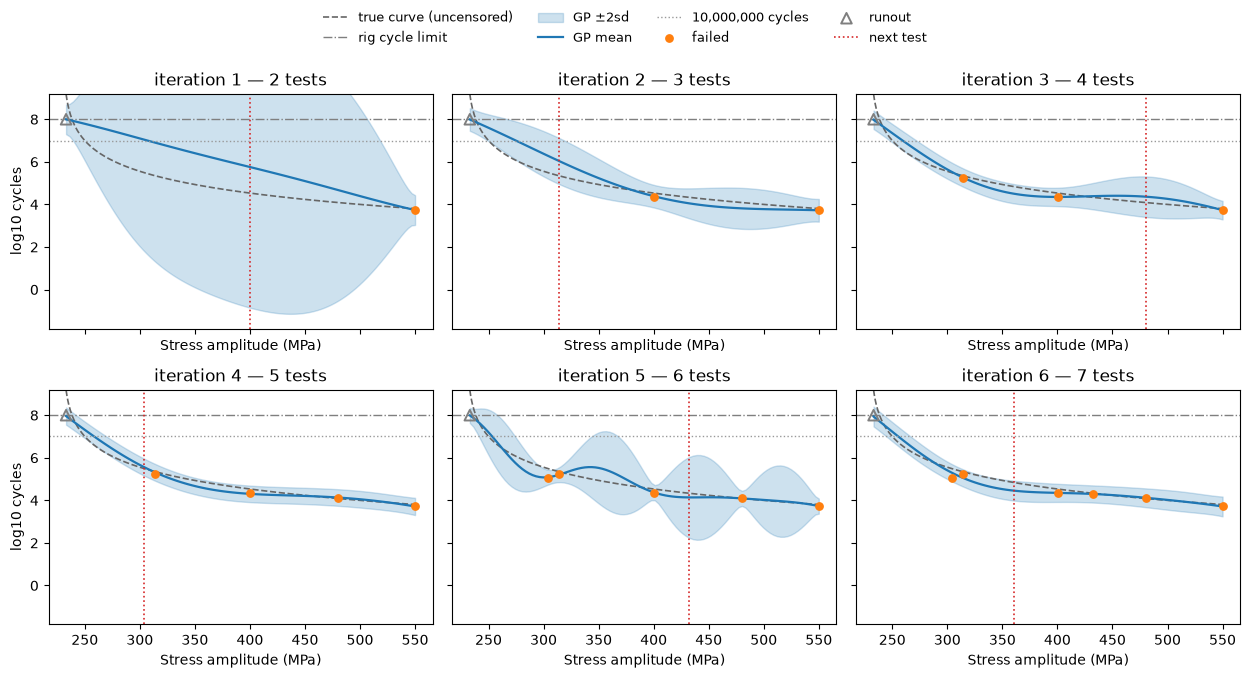

In [18]:
target_level = float(np.log10(TARGET_CYCLES))
true_strength = simulator.strength_for_life(target_level)
stress_grid = np.linspace(*BOUNDS, 400)
truth_curve = simulator.true_log_life(stress_grid)

print(f"the truth to beat: {true_strength:.2f} MPa survives "
      f"{TARGET_CYCLES:,.0f} cycles")
print(f"the true endurance limit is {simulator.endurance_limit:g} MPa")


def draw_specimens(ax, frame, size=28, label_prefix=""):
    """Failures as dots, runouts as up-arrows: a runout is a lower bound."""
    runout = frame[RUNOUT_COL].astype(bool).to_numpy()
    ax.scatter(frame.loc[~runout, STRESS_COL], frame.loc[~runout, LOG_CYCLES_COL],
               s=size, color=COLOURS["tests"], zorder=3,
               label=f"{label_prefix}failed")
    if runout.any():
        ax.scatter(frame.loc[runout, STRESS_COL], frame.loc[runout, LOG_CYCLES_COL],
                   s=size + 30, marker="^", facecolor="none",
                   edgecolor=COLOURS["runout"], lw=1.4, zorder=3,
                   label=f"{label_prefix}runout")


columns = 3
rows = int(np.ceil(len(history) / columns))
fig, axes = plt.subplots(
    rows, columns, figsize=(4.2 * columns, 3.4 * rows), sharex=True, sharey=True
)
axes = np.atleast_1d(axes).ravel()

for ax, step in zip(axes, history):
    panel = step["curve"]
    s = panel[STRESS_COL].to_numpy()
    mean, sd = panel["mean"].to_numpy(), panel["sd"].to_numpy()

    ax.plot(stress_grid, truth_curve, color=COLOURS["truth"], lw=1.2, ls="--",
            label="true curve (uncensored)")
    ax.axhline(RUNOUT_LOG_CYCLES, color=COLOURS["runout"], lw=1.0, ls="-.",
               label="rig cycle limit")
    ax.fill_between(s, mean - 2 * sd, mean + 2 * sd, alpha=0.22,
                    color=COLOURS["gp"], label="GP ±2sd")
    ax.plot(s, mean, color=COLOURS["gp"], lw=1.6, label="GP mean")
    ax.axhline(target_level, color="0.6", lw=1.0, ls=":",
               label=f"{TARGET_CYCLES:,.0f} cycles")
    draw_specimens(ax, step["observed"])
    for stress in step["picked"]:
        ax.axvline(stress, color=COLOURS["picked"], lw=1.2, ls=":", label="next test")

    # The count goes in the title: a shared legend can only carry one label,
    # so putting it there would show every panel the last panel's count.
    ax.set_title(f"iteration {step['iteration']} — {step['n_tests']} tests")

for ax in axes[len(history):]:
    ax.set_visible(False)
for ax in axes[:len(history)]:
    ax.set_xlabel(STRESS_COL)
for ax in axes[::columns]:
    ax.set_ylabel(LOG_CYCLES_COL)
axes[0].set_ylim(top=RUNOUT_LOG_CYCLES + 1.2)

handles, labels = axes[0].get_legend_handles_labels()
seen_labels = dict(zip(labels, handles))
fig.legend(seen_labels.values(), seen_labels.keys(), loc="upper center",
           ncol=4, frameon=False, fontsize=9)
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

### Where the acquisition chose to test

`qNIPV` reduces integrated posterior variance across the whole amplitude range.
It is not looking for the fatigue strength, and it does not know the design
life exists — so whether it concentrates near the crossing is a result, not a
design choice.

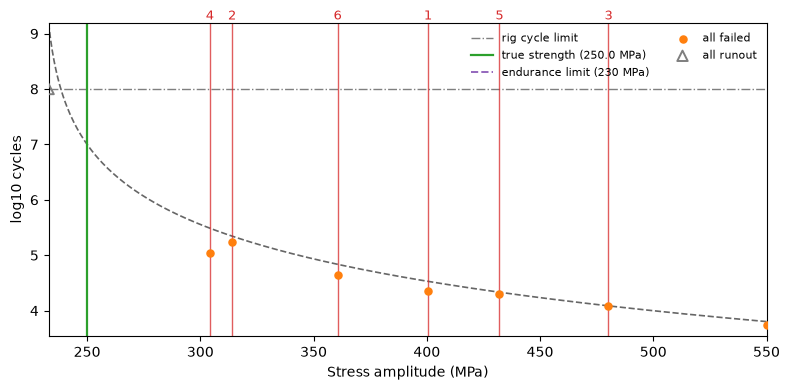

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(stress_grid, truth_curve, color=COLOURS["truth"], lw=1.2, ls="--")
ax.axhline(RUNOUT_LOG_CYCLES, color=COLOURS["runout"], lw=1.0, ls="-.",
           label="rig cycle limit")
ax.axvline(true_strength, color=COLOURS["true_strength"], lw=1.6,
           label=f"true strength ({true_strength:.1f} MPa)")
ax.axvline(simulator.endurance_limit, color=COLOURS["limit"], lw=1.4, ls="--",
           label=f"endurance limit ({simulator.endurance_limit:g} MPa)")
# The iteration labels are placed at the top of the axes, so the limits have to
# be settled before they are drawn.
ax.set_xlim(*BOUNDS)
ax.set_ylim(top=RUNOUT_LOG_CYCLES + 1.2)
for step in history:
    for stress in step["picked"]:
        ax.axvline(stress, color=COLOURS["picked"], lw=1.0, alpha=0.75)
        ax.annotate(str(step["iteration"]), (stress, ax.get_ylim()[1]),
                    ha="center", va="bottom", fontsize=9, color=COLOURS["picked"])
draw_specimens(ax, campaign, size=26, label_prefix="all ")

ax.set_xlabel(STRESS_COL)
ax.set_ylabel(LOG_CYCLES_COL)
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

### The posterior as a saved dataset

The **Predict slice** workflow writes the fitted posterior back into the
project as two datasets, where it outlives the job and can be opened in the GUI.

In [20]:
run_saved(client, project_id, saved_ids["Fatigue - Train model"])  # train on the final programme

posterior_curve = saved_prediction(
    client, project_id,
    run_saved(client, project_id, saved_ids["Fatigue - Predict slice"]),
)
print(f"saved as {MEAN_NAME!r} and {UNCERTAINTY_NAME!r} in the project")
posterior_curve.head()

saved as 'fatigue_gp_mean' and 'fatigue_gp_sd' in the project


,Stress amplitude (MPa),mean,sd
0,233.00,7.935915,0.214881
1,236.17,7.798168,0.211193
2,239.34,7.659992,0.209159
3,242.51,7.521764,0.208406
4,245.68,7.383867,0.208565


### Validation

Scored on its own training data, so these are a check that the fit took, not a
generalisation estimate. Note that the runouts are scored as if they were
measurements, which flatters the fit exactly where it is least trustworthy.

In [21]:
scores = outputs(run_saved(client, project_id, saved_ids["Fatigue - Validate"]))
as_frame(scores["Score_scores"])

,metric_name,score
0,MSE,0.012297
1,RMSE,0.110890
2,R2,0.992104


---
<a id="section-3"></a>
## 3. The fatigue strength, with its uncertainty

The GP is a good *interpolator*, but it has no notion of a fatigue strength:
reading one off a posterior mean gives a number with no uncertainty attached.
This section answers the question the programme is actually for, from the model
section 2 produced.

Take the posterior that section 2 saved and draw the design life
$\log_{10} N = 7$ across it as a horizontal line. Where the **posterior mean**
meets that line is the fatigue strength. Where the **credible band** still
contains it — from where the band's upper edge passes through the level to
where its lower edge does — is the interval: every amplitude at which the
material could still last exactly $10^7$ cycles.

This is the DBTT notebook's `dbtt_from_curve` with one change. There the level
was *derived* from the curve, as the mid-point of the two shelves it reached;
here the level is **given** by the design life, so the function takes it as an
argument and nothing is inferred from the extent of the slice.

> **Where the runouts bite.** Every censored specimen entered the GP at the
> rig's cycle limit, which is *below* its true life. The fitted curve is
> therefore pulled down at low amplitude, and taken on its own that moves the
> crossing of $\log_{10}N = 7$ to a **lower** amplitude than the truth — an
> error in the conservative direction, but an error.
>
> It is not the only one, and it is not always the largest. Section 4 finds
> the opposite sign in this run, because a sparse campaign interpolating
> across the curve's sharpest bend overshoots by more than the censoring
> undershoots. The point to carry forward is that the interval knows about
> neither: a credible band widens for variance, and both of these are
> **biases**. Keeping `TARGET_CYCLES` well below `RUNOUT_LOG_CYCLES` limits
> the damage; a real assessment uses a censored likelihood, which is a
> different model rather than a different kernel.

In [22]:
#@title Reading a design stress off a fitted slice { display-mode: "form" }
# Covers
#   crossing_from_curve()  where a fitted posterior crosses a level you supply,
#                          with the interval you get by inverting its credible
#                          band. The DBTT notebook's `dbtt_from_curve`, with
#                          the level given rather than derived from the curve.
#   CurveCrossing          what it returns - the crossing, the interval around
#                          it, the level and the gradient there.
#
# The posterior curve itself comes from the Engine (section 2). Everything
# here is arithmetic on that curve, so the cell needs nothing but numpy.


def _erfinv(mass: float) -> float:
    """Inverse error function at ``mass``, by bisection on ``math.erf``.

    Only ever called with one scalar, so a short bisection is cheaper to read
    than the rational approximation and avoids taking scipy back as a
    dependency for a single number.
    """
    import math

    lo, hi = 0.0, 6.0
    for _ in range(200):
        mid = 0.5 * (lo + hi)
        if math.erf(mid) < mass:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)


def _crossings(x: np.ndarray, y: np.ndarray, level: float):
    """Every (position, slope) where ``y`` crosses ``level``, interpolated."""
    above = y >= level
    out = []
    for i in np.flatnonzero(np.diff(above.astype(int)) != 0):
        x0, x1, y0, y1 = x[i], x[i + 1], y[i], y[i + 1]
        slope = (y1 - y0) / (x1 - x0)
        out.append((x0 + (level - y0) / slope if slope != 0 else x0, slope))
    return out


@dataclass
class CurveCrossing:
    """Where a fitted posterior reaches a given level, and how sure that is."""

    at: float                   # where the posterior mean crosses the level
    low: Optional[float]        # interval start; None if it runs off the slice
    high: Optional[float]       # interval end;   None if it runs off the slice
    has_band: bool              # False when no `sd` was given: no interval at all
    credible_mass: float        # the mass of the band that was inverted
    level: float                # the level being crossed
    gradient: float             # curve slope there; reported, not used
    n_crossings: int            # >1 means the mean is not monotonic

    @property
    def width(self) -> Optional[float]:
        """Interval width, or None if either end is unbounded."""
        if self.low is None or self.high is None:
            return None
        return self.high - self.low

    def __repr__(self) -> str:
        if not self.has_band:
            return f"CurveCrossing(at={self.at:.2f}, no band given)"
        fmt = lambda v: "unbounded" if v is None else f"{v:.2f}"
        return (f"CurveCrossing(at={self.at:.2f}, "
                f"{self.credible_mass:.0%} interval "
                f"[{fmt(self.low)}, {fmt(self.high)}])")


def crossing_from_curve(x, mean, level: float, sd=None,
                        credible_mass: float = 0.95) -> CurveCrossing:
    """Read off where a fitted posterior reaches ``level``, with its uncertainty.

    This works on a model's own posterior curve - the mean and standard
    deviation a GP predicts across a slice - rather than on the measurements.

    The interval is the band inverted. Draw ``level`` as a horizontal line
    across the credible band; the positions at which the band still contains
    that line are the positions at which the curve could still be at the
    level. Equivalently, the ends are where the band's two edges cross the
    level, and they are found the same way the crossing itself is - no
    linearisation, and no dividing by the gradient, so a shallow curve widens
    the interval instead of being flattered by it. The interval is asymmetric
    in general, which is the point.

    Two caveats travel with it. The band is *pointwise*, so inverting it gives
    approximately rather than exactly the nominal coverage. And the band is
    *predictive* - it carries the material's specimen-to-specimen scatter - so
    the interval answers "where could a fresh specimen reach this level?",
    which is wider than "where does the underlying curve reach it?".

    ``low`` or ``high`` come back as None when the band still straddles the
    level at the end of the slice: the data does not bound the answer on that
    side, and a wider slice is the fix.
    """
    x = np.asarray(x, dtype=float).reshape(-1)
    y = np.asarray(mean, dtype=float).reshape(-1)
    if x.size != y.size:
        raise ValueError(f"x and mean differ in length: {x.size} vs {y.size}")
    if x.size < 3:
        raise ValueError("need at least three points to locate a crossing")
    if not 0.0 < credible_mass < 1.0:
        raise ValueError(f"credible_mass must lie in (0, 1), got {credible_mass}")

    s = None
    if sd is not None:
        s = np.asarray(sd, dtype=float).reshape(-1)
        # Validate before reordering: indexing a short `sd` with the full
        # ordering raises IndexError rather than saying what is wrong.
        if s.size != x.size:
            raise ValueError(f"sd differs in length: {s.size} vs {x.size}")

    order = np.argsort(x)
    x, y = x[order], y[order]
    if s is not None:
        s = s[order]

    found = _crossings(x, y, level)
    if not found:
        raise ValueError(
            f"the posterior mean never reaches {level:g} across this slice; the "
            "level is outside what the model predicts here"
        )
    # The steepest crossing is the one the question is about; others are wiggle.
    at, gradient = max(found, key=lambda c: abs(c[1]))

    low = high = None
    if s is not None:
        # The two-sided z for this mass, without pulling scipy in for one number.
        z = float(np.sqrt(2.0) * _erfinv(credible_mass))
        hi_edge, lo_edge = y + z * s, y - z * s

        # Where the band straddles the level at all. The mean crosses inside
        # this set by construction, so the run containing the crossing is the
        # interval; other runs belong to other crossings.
        inside = (lo_edge <= level) & (level <= hi_edge)
        here = int(np.argmin(np.abs(x - at)))
        if not inside[here]:                      # only reachable on a tie at
            here = int(np.flatnonzero(inside)[0]) # the very edge of a cell

        start = stop = here
        while start > 0 and inside[start - 1]:
            start -= 1
        while stop < x.size - 1 and inside[stop + 1]:
            stop += 1

        # Refine each end onto whichever edge actually closes the band there.
        # Which one that is depends on the direction of the curve: on a rising
        # curve the band opens as its upper edge reaches the level and shuts as
        # its lower edge passes it, and on a falling curve the roles swap.
        # Picking by `inside` rather than by assumption handles both, and fatigue
        # life falls with amplitude where Charpy energy rises with temperature.
        def close(outside: int, a: int, b: int) -> float:
            edge = hi_edge if hi_edge[outside] < level else lo_edge
            x0, x1, e0, e1 = x[a], x[b], edge[a], edge[b]
            return float(x0 + (level - e0) * (x1 - x0) / (e1 - e0)) if e1 != e0 else float(x0)

        if start > 0:
            low = close(start - 1, start - 1, start)
        if stop < x.size - 1:
            high = close(stop + 1, stop, stop + 1)

    return CurveCrossing(
        at=float(at), low=low, high=high, has_band=s is not None,
        credible_mass=float(credible_mass), level=float(level),
        gradient=float(gradient), n_crossings=len(found),
    )

In [23]:
read = crossing_from_curve(
    posterior_curve[STRESS_COL], posterior_curve["mean"], target_level,
    sd=posterior_curve["sd"],
)
print(read)
print(f"  target level: log10 N = {read.level:.2f}  ({TARGET_CYCLES:,.0f} cycles)")
print(f"  gradient there: {read.gradient:.4f} decades/MPa")
print(f"  interval width: {read.width:.2f} MPa"
      if read.width is not None else
      "  interval unbounded on one side - widen BOUNDS")
print(f"  mean crossings found: {read.n_crossings}")

CurveCrossing(at=254.62, 95% interval [245.11, 264.74])
  target level: log10 N = 7.00  (10,000,000 cycles)
  gradient there: -0.0425 decades/MPa
  interval width: 19.63 MPa
  mean crossings found: 1


### How it compares to the truth

The simulator's S–N curve implies a fatigue strength exactly, so the estimate
can be scored. Watch the **sign** of the error as well as its size: censoring
biases the estimate low, so an error that is negative is the one the model was
always going to make.

In [24]:
low, high = read.low, read.high
contains = (low is not None and high is not None
            and low <= true_strength <= high)

# An end is None when the band never closed inside BOUNDS. Say so rather than
# formatting it as a number.
show = lambda v: "unbounded" if v is None else f"{v:.2f}"
print(f"{read.credible_mass:.0%} interval [{show(low)}, {show(high)}] MPa "
      f"{'contains' if contains else 'does NOT contain'} the true fatigue strength "
      f"({true_strength:.2f} MPa)")
if low is not None and high is not None:
    print(f"  the estimate sits {read.at - low:.2f} MPa above the lower end and "
          f"{high - read.at:.2f} MPa below the upper one - the interval is "
          "asymmetric, which a +/- number cannot say")

pd.DataFrame([
    {"quantity": "GP crossing", "strength (MPa)": read.at,
     "low": np.nan if low is None else low,
     "high": np.nan if high is None else high,
     "width (MPa)": np.nan if read.width is None else read.width},
    {"quantity": "truth", "strength (MPa)": true_strength,
     "low": np.nan, "high": np.nan, "width (MPa)": np.nan},
]).round(2)

95% interval [245.11, 264.74] MPa contains the true fatigue strength (250.00 MPa)
  the estimate sits 9.51 MPa above the lower end and 10.12 MPa below the upper one - the interval is asymmetric, which a +/- number cannot say


,quantity,strength (MPa),low,high,width (MPa)
0,GP crossing,254.62,245.11,264.74,19.63
1,truth,250.00,NaN,NaN,NaN


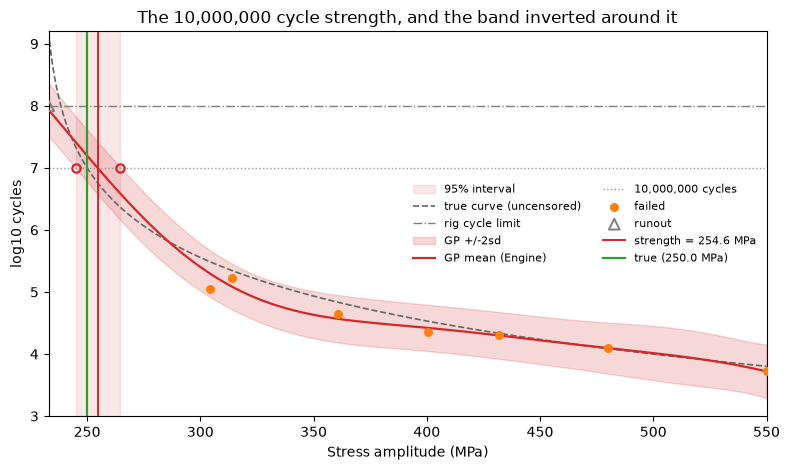

In [25]:
s_curve = posterior_curve[STRESS_COL].to_numpy()
mean_curve = posterior_curve["mean"].to_numpy()
sd_curve = posterior_curve["sd"].to_numpy()

fig, ax = plt.subplots(figsize=(8, 4.8))

# An unbounded end is drawn out to the edge of the tested range, where the
# band stopped closing - not as a bound the programme actually established.
span_low = BOUNDS[0] if low is None else low
span_high = BOUNDS[1] if high is None else high
ax.axvspan(span_low, span_high, color=COLOURS["strength"], alpha=0.10,
           label=f"{read.credible_mass:.0%} interval")
ax.plot(stress_grid, truth_curve, color=COLOURS["truth"], lw=1.2, ls="--",
        label="true curve (uncensored)")
ax.axhline(RUNOUT_LOG_CYCLES, color=COLOURS["runout"], lw=1.0, ls="-.",
           label="rig cycle limit")
ax.fill_between(s_curve, mean_curve - 2 * sd_curve, mean_curve + 2 * sd_curve,
                color=COLOURS["posterior"], alpha=0.18, label="GP +/-2sd")
ax.plot(s_curve, mean_curve, color=COLOURS["posterior"], lw=1.6,
        label="GP mean (Engine)")
ax.axhline(target_level, color="0.6", lw=1.0, ls=":",
           label=f"{TARGET_CYCLES:,.0f} cycles")

# The construction, drawn: the level meets the band here and leaves it there.
for edge in (low, high):
    if edge is not None:
        ax.plot([edge], [target_level], marker="o", ms=6, mfc="none",
                mec=COLOURS["strength"], mew=1.6, zorder=4)

draw_specimens(ax, campaign, size=30)
ax.axvline(read.at, color=COLOURS["strength"], lw=1.4,
           label=f"strength = {read.at:.1f} MPa")
ax.axvline(true_strength, color=COLOURS["true_strength"], lw=1.6,
           label=f"true ({true_strength:.1f} MPa)")

ax.set_xlim(*BOUNDS)
ax.set_ylim(top=RUNOUT_LOG_CYCLES + 1.2)
ax.set_xlabel(STRESS_COL)
ax.set_ylabel(LOG_CYCLES_COL)
ax.set_title(f"The {TARGET_CYCLES:,.0f} cycle strength, and the band inverted around it")
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

### The estimate against the specimen count

Each iteration's curve gives a fatigue strength and an interval, so the whole
history can be replayed. Expect the estimate to move and the interval to
breathe rather than shrink monotonically: the band is predictive, so it floors
at the material's own scatter, and an early specimen placed somewhere
informative can tighten things more than three placed later.

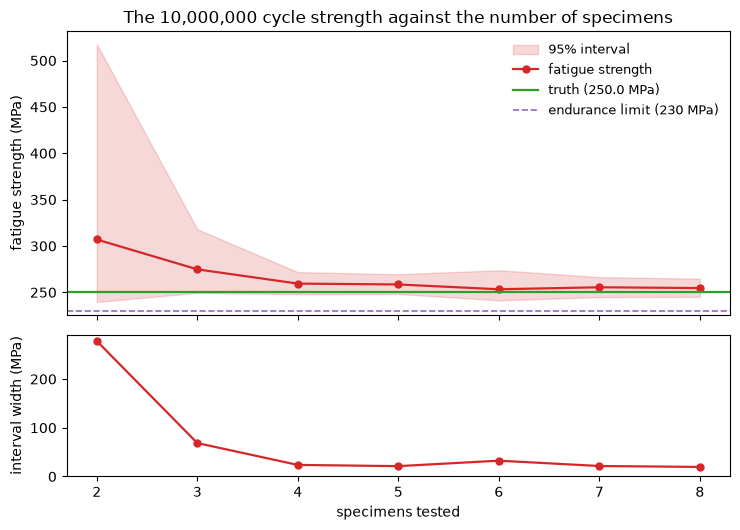

,n_tests,strength,low,high,width
0,2,307.00,239.61,517.62,278.01
1,3,274.82,249.45,318.09,68.63
2,4,259.42,248.03,271.78,23.75
3,5,258.51,248.23,269.50,21.26
4,6,253.32,241.36,273.83,32.47
5,7,255.46,244.89,266.43,21.54
6,8,254.62,245.11,264.74,19.63


In [26]:
track = []
for step in history:
    panel = step["curve"]
    try:
        step_read = crossing_from_curve(panel[STRESS_COL], panel["mean"],
                                        target_level, sd=panel["sd"])
    except ValueError:
        continue  # an early GP need not reach the design life anywhere on the slice
    track.append({
        "n_tests": step["n_tests"], "strength": step_read.at,
        # None means the band never closed within BOUNDS; NaN leaves a visible
        # gap in the figure rather than inventing a bound that is not there.
        "low": np.nan if step_read.low is None else step_read.low,
        "high": np.nan if step_read.high is None else step_read.high,
    })

# `history` records each iteration *before* its pick is tested, so the final
# programme is only represented by the read made at the top of section 3.
track.append({"n_tests": len(campaign), "strength": read.at,
              "low": np.nan if low is None else low,
              "high": np.nan if high is None else high})
track = pd.DataFrame(track)
track["width"] = track["high"] - track["low"]

fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(7.5, 5.4), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
)

top.fill_between(track["n_tests"], track["low"], track["high"],
                 color=COLOURS["strength"], alpha=0.18,
                 label=f"{read.credible_mass:.0%} interval")
top.plot(track["n_tests"], track["strength"], "o-", color=COLOURS["strength"],
         lw=1.6, ms=5, label="fatigue strength")
top.axhline(true_strength, color=COLOURS["true_strength"], lw=1.6,
            label=f"truth ({true_strength:.1f} MPa)")
top.axhline(simulator.endurance_limit, color=COLOURS["limit"], lw=1.2, ls="--",
            label=f"endurance limit ({simulator.endurance_limit:g} MPa)")
top.set_ylabel("fatigue strength (MPa)")
top.legend(frameon=False, fontsize=9)
top.set_title(f"The {TARGET_CYCLES:,.0f} cycle strength against the number of specimens")

bottom.plot(track["n_tests"], track["width"], "o-", color=COLOURS["strength"],
            lw=1.6, ms=5)
bottom.set_xlabel("specimens tested")
bottom.set_ylabel("interval width (MPa)")
bottom.set_ylim(bottom=0)

fig.tight_layout()
plt.show()

track.round(2)

---
<a id="section-4"></a>
## 4. Was the active learning worth it?

Everything so far assumed that choosing *where* to test beats deciding in
advance. This section tests that, by running three fixed designs through
exactly the same machinery — upload, train on the Engine, predict the slice,
invert the band — and putting their answers beside the active-learning one.

| Design | Specimens | The idea |
| --- | --- | --- |
| Evenly spaced, 10 | 10 | The obvious thing to do with a small budget |
| Evenly spaced, 30 | 30 | The same idea with three times the specimens |
| 10 amplitudes, 3 repeats | 30 | The same budget as above, spent on replication instead of resolution |

The third is the interesting one, and it is the one a fatigue standard would
actually ask for. Fatigue scatter is large, so replication is how the scatter
itself gets characterised, and staircase and Probit methods for the endurance
limit are built entirely out of repeats. The question is whether thirty
specimens at ten amplitudes tell you more about the *fatigue strength* than
thirty specimens at thirty amplitudes.

> **What this comparison is and is not.** Every design is one realisation,
> drawn from the same simulator with the same noise settings. Differences of a
> megapascal or two are noise, not evidence, and a fair benchmark would repeat
> each design over many seeds and compare the *distribution* of intervals. What
> a single run can show is the shape of the thing: whether a design brackets
> the truth at all, and roughly what it costs to do so.
>
> Nor is specimen count the only currency. An S–N programme is budgeted in
> **rig hours**, and a runout costs the full cycle limit while a low-cycle
> failure is over in an afternoon. The table reports how many specimens each
> design spends as runouts, which is the number that decides how long the
> programme takes.

In [27]:
BASELINES = [
    ("Evenly spaced, 10", np.linspace(*BOUNDS, 10)),
    ("Evenly spaced, 30", np.linspace(*BOUNDS, 30)),
    ("10 amplitudes, 3 repeats", np.repeat(np.linspace(*BOUNDS, 10), 3)),
]


def run_fixed_design(label: str, stresses) -> dict:
    """Take one fixed design all the way to a fatigue strength, through the Engine.

    The same path section 2 took, minus the loop: upload the programme, train a
    GP on it, predict across the slice, and invert the band. Each design gets
    its own resources so nothing here disturbs the active-learning ones, and
    re-running the notebook versions them in place rather than piling up.
    """
    slug = label.lower().replace(",", "").replace(" ", "_")
    design = simulator.run(list(map(float, stresses)), start_index=1)

    dataset = upload_dataset(client, project_id, design, f"fatigue_baseline_{slug}")
    training = build_training_workflow(
        client, project_id, dataset, f"fatigue_gp_{slug}",
        kernel=KERNEL, model_type=MODEL_TYPE, warp_inputs=WARP_INPUTS, seed=MODEL_SEED,
    )
    run_saved(client, project_id,
              save_workflow(client, project_id, training, f"Fatigue baseline train - {label}"))
    model = resource_id(client, project_id, f"fatigue_gp_{slug}", "model")

    prediction = build_prediction_workflow(
        client, project_id, model, BOUNDS,
        f"fatigue_mean_{slug}", f"fatigue_sd_{slug}",
    )
    response = run_saved(client, project_id,
                         save_workflow(client, project_id, prediction,
                                       f"Fatigue baseline predict - {label}"))
    curve = saved_prediction(client, project_id, response)

    return {"label": label, "design": design, "curve": curve,
            "read": crossing_from_curve(curve[STRESS_COL], curve["mean"],
                                        target_level, sd=curve["sd"])}


results = []
for label, stresses in BASELINES:
    print(f"{label} ({len(stresses)} specimens) ...", end=" ", flush=True)
    results.append(run_fixed_design(label, stresses))
    print(results[-1]["read"])

Evenly spaced, 10 (10 specimens) ... 

CurveCrossing(at=250.76, 95% interval [245.06, 256.91])
Evenly spaced, 30 (30 specimens) ... 

CurveCrossing(at=248.64, 95% interval [243.04, 254.49])
10 amplitudes, 3 repeats (30 specimens) ... 

CurveCrossing(at=249.36, 95% interval [243.39, 256.01])


### Side by side

In [28]:
def summarise(label: str, design: pd.DataFrame, at) -> dict:
    inside = (at.low is not None and at.high is not None
              and at.low <= true_strength <= at.high)
    return {"design": label, "specimens": len(design),
            "runouts": int(design[RUNOUT_COL].astype(bool).sum()),
            "strength (MPa)": at.at,
            "low": np.nan if at.low is None else at.low,
            "high": np.nan if at.high is None else at.high,
            "width (MPa)": np.nan if at.width is None else at.width,
            "error (MPa)": at.at - true_strength,
            "contains truth": inside}


comparison = pd.DataFrame(
    [summarise(f"Active learning ({ACQUISITION})", campaign, read)]
    + [summarise(r["label"], r["design"], r["read"]) for r in results]
)
comparison.round(2)

,design,specimens,runouts,strength (MPa),low,high,width (MPa),error (MPa),contains truth
0,Active learning (qNIPV),8,1,254.62,245.11,264.74,19.63,4.63,True
1,"Evenly spaced, 10",10,1,250.76,245.06,256.91,11.85,0.77,True
2,"Evenly spaced, 30",30,1,248.64,243.04,254.49,11.45,-1.36,True
3,"10 amplitudes, 3 repeats",30,3,249.36,243.39,256.01,12.62,-0.64,True


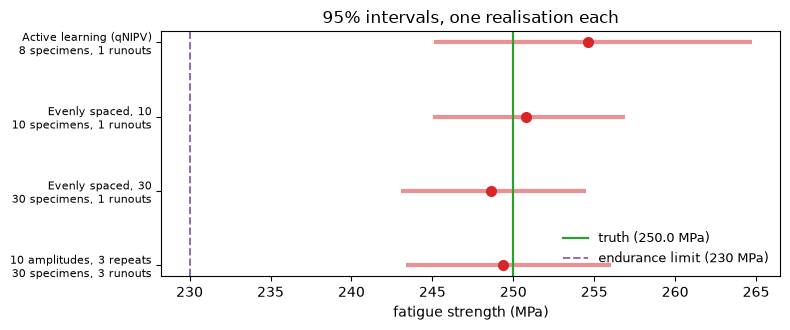

In [29]:
fig, ax = plt.subplots(figsize=(8, 3.4))

rows = comparison.iloc[::-1].reset_index(drop=True)   # first design at the top
for y, row in rows.iterrows():
    colour = COLOURS["strength"] if row["contains truth"] else "firebrick"
    ax.plot([row["low"], row["high"]], [y, y], lw=3, color=colour, alpha=0.5,
            solid_capstyle="butt")
    ax.plot([row["strength (MPa)"]], [y], "o", ms=7, color=colour)

ax.axvline(true_strength, color=COLOURS["true_strength"], lw=1.6,
           label=f"truth ({true_strength:.1f} MPa)")
ax.axvline(simulator.endurance_limit, color=COLOURS["limit"], lw=1.4, ls="--",
           label=f"endurance limit ({simulator.endurance_limit:g} MPa)")
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([f"{r['design']}\n{r['specimens']} specimens, "
                    f"{r['runouts']} runouts" for _, r in rows.iterrows()], fontsize=8)
ax.set_xlabel("fatigue strength (MPa)")
ax.set_title(f"{read.credible_mass:.0%} intervals, one realisation each")
ax.legend(frameon=False, fontsize=9, loc="lower right")
fig.tight_layout()
plt.show()

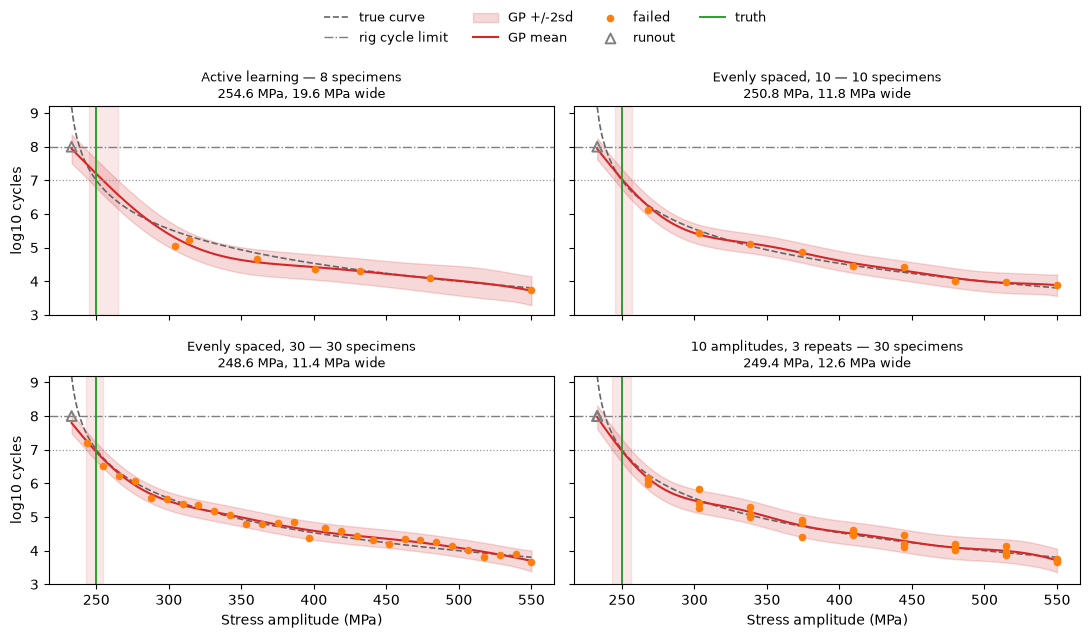

In [30]:
panels = [("Active learning", campaign, posterior_curve, read)] + [
    (r["label"], r["design"], r["curve"], r["read"]) for r in results
]

fig, axes = plt.subplots(2, 2, figsize=(11, 6.4), sharex=True, sharey=True)
for ax, (label, design, curve, at) in zip(axes.ravel(), panels):
    stress = curve[STRESS_COL].to_numpy()
    mean, sd = curve["mean"].to_numpy(), curve["sd"].to_numpy()

    if at.low is not None and at.high is not None:
        ax.axvspan(at.low, at.high, color=COLOURS["strength"], alpha=0.10)
    ax.plot(stress_grid, truth_curve, color=COLOURS["truth"], lw=1.2, ls="--",
            label="true curve")
    ax.axhline(RUNOUT_LOG_CYCLES, color=COLOURS["runout"], lw=1.0, ls="-.",
               label="rig cycle limit")
    ax.fill_between(stress, mean - 2 * sd, mean + 2 * sd,
                    color=COLOURS["posterior"], alpha=0.18, label="GP +/-2sd")
    ax.plot(stress, mean, color=COLOURS["posterior"], lw=1.5, label="GP mean")
    ax.axhline(at.level, color="0.6", lw=0.9, ls=":")
    draw_specimens(ax, design, size=20)
    ax.axvline(true_strength, color=COLOURS["true_strength"], lw=1.4, label="truth")

    width = "unbounded" if at.width is None else f"{at.width:.1f} MPa wide"
    ax.set_title(f"{label} — {len(design)} specimens\n{at.at:.1f} MPa, {width}",
                 fontsize=9)

axes[0, 0].set_ylim(top=RUNOUT_LOG_CYCLES + 1.2)
for ax in axes[-1]:
    ax.set_xlabel(STRESS_COL)
for ax in axes[:, 0]:
    ax.set_ylabel(LOG_CYCLES_COL)

handles, labels = axes[0, 0].get_legend_handles_labels()
seen_labels = dict(zip(labels, handles))
fig.legend(seen_labels.values(), seen_labels.keys(),
           loc="upper center", ncol=4, frameon=False, fontsize=9)
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

### What that says

**Active learning came last here too**, and for a recognisably similar reason:

| Design | Specimens | Runouts | Width | Error |
| --- | --- | --- | --- | --- |
| Evenly spaced, 30 | 30 | 1 | **11.45 MPa** | −1.36 |
| Evenly spaced, 10 | 10 | 1 | 11.85 MPa | **+0.77** |
| 10 amplitudes, 3 repeats | 30 | 3 | 12.62 MPa | −0.64 |
| Active learning (qNIPV) | 8 | 1 | 19.63 MPa | +4.63 |

Part of that gap is simply budget — eight specimens against ten and thirty.
But ten evenly spaced specimens gave an interval 40% narrower than eight chosen
ones, and 25% more specimens does not buy 40%. The placement is doing the work.

**The acquisition avoided the region the answer lives in.** Its six picks ran
from 304.2 MPa to 480.2 MPa. The fatigue strength is at 250 MPa. Between its
lowest failure and the seed runout at 233 MPa it left a **71 MPa gap**, and
that gap covers the sharpest bend in the whole S–N curve — the part where life
begins to run away towards the endurance limit.

**The runout is what misled it.** A censored specimen enters the GP as an
ordinary number, so the model sees a confident observation at the bottom of the
range and `qNIPV`, finding little variance to reduce there, spends its budget
elsewhere. Censoring does not only bias the fit, as section 3 warned; it
misdirects the campaign that is supposed to repair the fit.

**The error came out the opposite way round from section 3's warning**, and it
is worth being exact about why. Censoring records the 233 MPa runout at
$10^{8.00}$ cycles when its true life is $10^{9.19}$, which pulls the
low-amplitude end of the fitted curve *down* and, on its own, moves the
crossing to a **lower** amplitude — an error in the conservative direction.
What actually dominated is the gap. Interpolating smoothly across a strongly
convex region sits above the truth: at 250 MPa the true life is $10^{7.00}$,
while a straight line between the two bracketing observations gives $10^{7.40}$
even *with* the censored anchor, and $10^{8.30}$ without it. A curve that is
too high near 250 MPa crosses the design life at too high an amplitude, which
is how the estimate came out at 254.62 MPa — unconservative. So the censoring
bias is real, and here it partly *offset* a larger sampling error pointing the
other way. Neither is covered by the interval, because a credible band widens
for variance and not for bias.

**Replication bought nothing.** The repeats design spent three of its thirty
specimens as runouts, all establishing the same fact — that life at the lowest
amplitude exceeds the rig limit — and finished with a wider interval than the
thirty spread across the range. Replication characterises *scatter*, which is
not what the fatigue strength is limited by once there are enough specimens to
pin the curve.

**One honest qualification.** Each design is a single realisation; differences
of a megapascal are noise, and the ordering of the top three is not meaningful.
What is meaningful is the gap between them and the active-learning row, and the
mechanism above is visible in the figures rather than inferred from the table.

---
## Notes

- **The interval is the deliverable, not the point estimate.** A programme of
  this size pins the fatigue strength down to a few megapascals; quoting a
  single number hides that, and an allowable stress is exactly the kind of
  number that gets quoted without one.
- **Runouts are censored, and this notebook does not treat them as such.**
  A runout says "the life exceeds the limit", and entering it *at* the limit
  tells the model something false and specific: that the life equals the limit.
  The fitted curve is pulled down at low amplitude and the strength comes out
  optimistic. No credible band widens to cover that, because censoring is a
  bias rather than a variance. Doing it properly means a censored likelihood —
  a Tobit-style model, or survival regression — which is a different model, not
  a different kernel, and is not something `ModelConfig` can be asked for.
  Keeping `TARGET_CYCLES` well below `RUNOUT_LOG_CYCLES` is damage limitation,
  not a fix.
- **The endurance limit is a harder question than the fatigue strength.** The
  fatigue strength at a stated life is a crossing, and a crossing is something
  a fitted curve can be asked for. The endurance limit is an *asymptote* — a
  knee with no finite life below it — and a GP has no notion of one. That is
  why this notebook asks for the $10^7$ cycle strength and not for $S_e$,
  even though $S_e$ is what the simulator was parameterised with.
- **The band is pointwise, so the coverage is approximate.** The interval is
  the set of amplitudes at which a pointwise credible band still contains the
  design life. Inverting a pointwise band does not give exactly the nominal
  mass — a simultaneous band would, and would be wider. What it does avoid is
  the delta method's linearisation: nothing here is divided by the slope of
  the S–N curve, so a flat, poorly resolved curve widens the interval instead
  of being flattered by it, and the result is asymmetric in general.
- **The band is predictive, so the interval is conservative.** It carries the
  material's specimen-to-specimen scatter, which means it answers "at what
  amplitude could a fresh specimen last exactly $10^7$ cycles?" rather than
  "where does the underlying S–N curve cross it?". The second is the narrower
  question and the one a design code wants; separating them needs the epistemic
  part of the variance on its own, which the Engine does not return.
- **An end can be unbounded.** If the band still straddles the design life at
  the edge of the slice, that end comes back as `None`: the programme does not
  bound the strength on that side. Widen `BOUNDS` rather than reporting a
  number the data does not support — though note that widening downwards runs
  into the endurance limit, below which there is nothing to measure.
- **Log life, not life.** The GP is trained on $\log_{10} N_f$. Fitting raw
  cycles would put almost all the residual weight on the long tests and leave
  the low-cycle end unconstrained, and the scatter really is multiplicative:
  fatigue data is quoted as a factor on life, not a number of cycles.